In [ ]:
from google.colab import files

uploaded = files.upload()

Saving customer_support_tickets.csv to customer_support_tickets.csv


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("customer_support_tickets.csv")

df.head()
print(df)

      Ticket ID        Customer Name              Customer Email  \
0             1        Marisa Obrien  carrollallison@example.com   
1             2         Jessica Rios    clarkeashley@example.com   
2             3  Christopher Robbins   gonzalestracy@example.com   
3             4     Christina Dillon    bradleyolson@example.org   
4             5    Alexander Carroll     bradleymark@example.com   
...         ...                  ...                         ...   
8464       8465           David Todd          adam28@example.net   
8465       8466           Lori Davis       russell68@example.com   
8466       8467      Michelle Kelley        ashley83@example.org   
8467       8468     Steven Rodriguez         fpowell@example.org   
8468       8469      Steven Davis MD          lori20@example.net   

      Customer Age Customer Gender       Product Purchased Date of Purchase  \
0               32           Other              GoPro Hero       2021-03-22   
1               42       

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print ("\n\nStatistical summary")
df.describe(include="all")

Dataset Shape: (8469, 17)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   object 
 2   Customer Email                8469 non-null   object 
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   object 
 5   Product Purchased             8469 non-null   object 
 6   Date of Purchase              8469 non-null   object 
 7   Ticket Type                   8469 non-null   object 
 8   Ticket Subject                8469 non-null   object 
 9   Ticket Description            8469 non-null   object 
 10  Ticket Status                 8469 non-null   object 
 11  Resolution                    2769 non-null   object 
 12  Ticket Priorit

,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
count,8469.000000,8469,8469,8469.000000,8469,8469,8469,8469,8469,8469,8469,2769,8469,8469,5650,2769,2769.000000
unique,NaN,8028,8320,NaN,3,42,730,5,16,8077,3,2769,4,4,5470,2728,NaN
top,NaN,Michael Garcia,bsmith@example.com,NaN,Male,Canon EOS,2020-10-21,Refund request,Refund request,I'm having an issue with the {product_purchase...,Pending Customer Response,Case maybe show recently my computer follow.,Medium,Email,2023-06-01 20:45:39,2023-06-01 17:14:42,NaN
freq,NaN,5,4,NaN,2896,240,24,1752,576,25,2881,1,2192,2143,3,3,NaN
mean,4235.000000,NaN,NaN,44.026804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.991333
std,2444.934048,NaN,NaN,15.296112,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.407016
min,1.000000,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000
25%,2118.000000,NaN,NaN,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000
50%,4235.000000,NaN,NaN,44.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000
75%,6352.000000,NaN,NaN,57.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000


In [15]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nColumns:")
print(df.columns.tolist())

Missing Values:
Ticket ID                          0
Customer Name                      0
Customer Email                     0
Customer Age                       0
Customer Gender                    0
Product Purchased                  0
Date of Purchase                   0
Ticket Type                        0
Ticket Subject                     0
Ticket Description                 0
Ticket Status                      0
Resolution                      5700
Ticket Priority                    0
Ticket Channel                     0
First Response Time             2819
Time to Resolution              5700
Customer Satisfaction Rating    5700
dtype: int64

Duplicate Rows: 0

Columns:
['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age', 'Customer Gender', 'Product Purchased', 'Date of Purchase', 'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status', 'Resolution', 'Ticket Priority', 'Ticket Channel', 'First Response Time', 'Time to Resolution', 'Customer Satisfacti

data cleaning

In [16]:
df_clean = df.copy()

print("Missing values before cleaning:")
print(df_clean.isnull().sum())

Missing values before cleaning:
Ticket ID                          0
Customer Name                      0
Customer Email                     0
Customer Age                       0
Customer Gender                    0
Product Purchased                  0
Date of Purchase                   0
Ticket Type                        0
Ticket Subject                     0
Ticket Description                 0
Ticket Status                      0
Resolution                      5700
Ticket Priority                    0
Ticket Channel                     0
First Response Time             2819
Time to Resolution              5700
Customer Satisfaction Rating    5700
dtype: int64


In [17]:
print("Duplicate rows:", df_clean.duplicated().sum())

print("\nDuplicate Ticket IDs:",
      df_clean["Ticket ID"].duplicated().sum())

df_clean["Date of Purchase"] = pd.to_datetime(
    df_clean["Date of Purchase"])

df_clean["First Response Time"] = pd.to_datetime(
    df_clean["First Response Time"])

print("\nDate conversion completed.\n")
df_clean.info()

Duplicate rows: 0

Duplicate Ticket IDs: 0

Date conversion completed.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Ticket ID                     8469 non-null   int64         
 1   Customer Name                 8469 non-null   object        
 2   Customer Email                8469 non-null   object        
 3   Customer Age                  8469 non-null   int64         
 4   Customer Gender               8469 non-null   object        
 5   Product Purchased             8469 non-null   object        
 6   Date of Purchase              8469 non-null   datetime64[ns]
 7   Ticket Type                   8469 non-null   object        
 8   Ticket Subject                8469 non-null   object        
 9   Ticket Description            8469 non-null   object        
 10  Ticket Status           

In [18]:
df_clean.to_csv("customer_support_tickets_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Dataset shape:", df_clean.shape)

Cleaned dataset saved successfully!
Dataset shape: (8469, 17)


In [19]:
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate rows after cleaning:",
      df_clean.duplicated().sum())

print("\nFinal dataset shape:", df_clean.shape)

Missing values after cleaning:
Ticket ID                          0
Customer Name                      0
Customer Email                     0
Customer Age                       0
Customer Gender                    0
Product Purchased                  0
Date of Purchase                   0
Ticket Type                        0
Ticket Subject                     0
Ticket Description                 0
Ticket Status                      0
Resolution                      5700
Ticket Priority                    0
Ticket Channel                     0
First Response Time             2819
Time to Resolution              5700
Customer Satisfaction Rating    5700
dtype: int64

Duplicate rows after cleaning: 0

Final dataset shape: (8469, 17)


In [20]:
print(df["First Response Time"].head(10))
print(df["Time to Resolution"].head(10))

0    2023-06-01 12:15:36
1    2023-06-01 16:45:38
2    2023-06-01 11:14:38
3    2023-06-01 07:29:40
4    2023-06-01 00:12:42
5                    NaN
6                    NaN
7                    NaN
8    2023-06-01 10:32:47
9    2023-06-01 09:25:48
Name: First Response Time, dtype: object
0                    NaN
1                    NaN
2    2023-06-01 18:05:38
3    2023-06-01 01:57:40
4    2023-06-01 19:53:42
5                    NaN
6                    NaN
7                    NaN
8                    NaN
9                    NaN
Name: Time to Resolution, dtype: object


data analysis


In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print(df["Ticket Status"].value_counts())

Ticket Status
Pending Customer Response    2881
Open                         2819
Closed                       2769
Name: count, dtype: int64


In [22]:
print(df["Ticket Type"].value_counts())

Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64


In [ ]:
print(df["Ticket Priority"].value_counts())

Ticket Priority
Medium      2192
Critical    2129
High        2085
Low         2063
Name: count, dtype: int64


In [ ]:
print(df["Ticket Channel"].value_counts())

Ticket Channel
Email           2143
Phone           2132
Social media    2121
Chat            2073
Name: count, dtype: int64


In [ ]:
print("Average Customer Satisfaction Rating:")
print(df["Customer Satisfaction Rating"].mean())

print("\nSatisfaction Rating Counts:")
print(df["Customer Satisfaction Rating"].value_counts().sort_index())

Average Customer Satisfaction Rating:
2.991332611050921

Satisfaction Rating Counts:
Customer Satisfaction Rating
1.0    553
2.0    549
3.0    580
4.0    543
5.0    544
Name: count, dtype: int64


In [ ]:
columns = [
    "Resolution",
    "Time to Resolution",
    "Customer Satisfaction Rating"
]

for status, data in df.groupby("Ticket Status"):
    print("\nStatus:", status)
    print(data[columns].isna().sum())


Status: Closed
Resolution                      0
Time to Resolution              0
Customer Satisfaction Rating    0
dtype: int64

Status: Open
Resolution                      2819
Time to Resolution              2819
Customer Satisfaction Rating    2819
dtype: int64

Status: Pending Customer Response
Resolution                      2881
Time to Resolution              2881
Customer Satisfaction Rating    2881
dtype: int64


data visualization

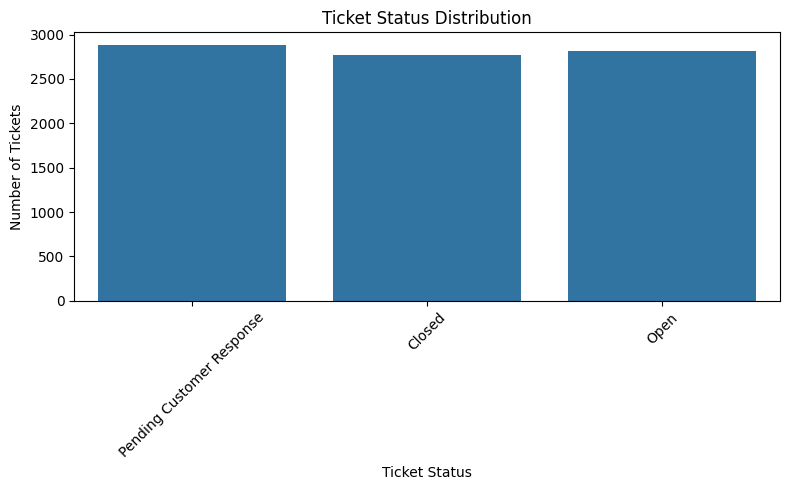

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Ticket Status")
plt.title("Ticket Status Distribution")
plt.xlabel("Ticket Status")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

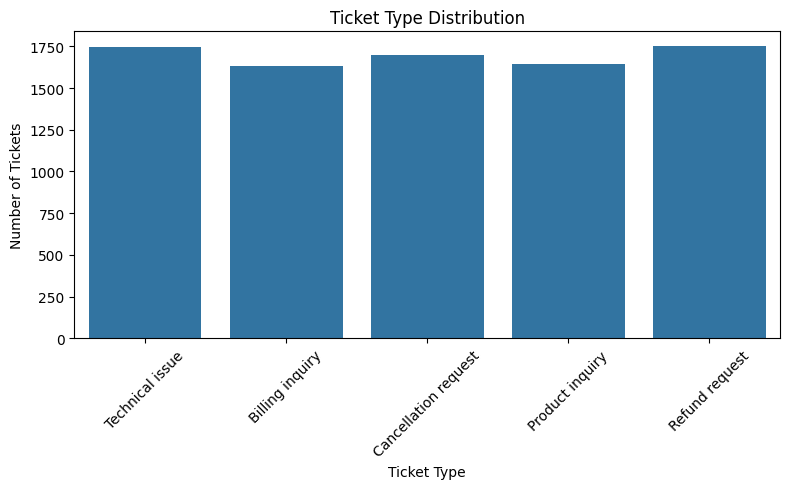

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Ticket Type")
plt.title("Ticket Type Distribution")
plt.xlabel("Ticket Type")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

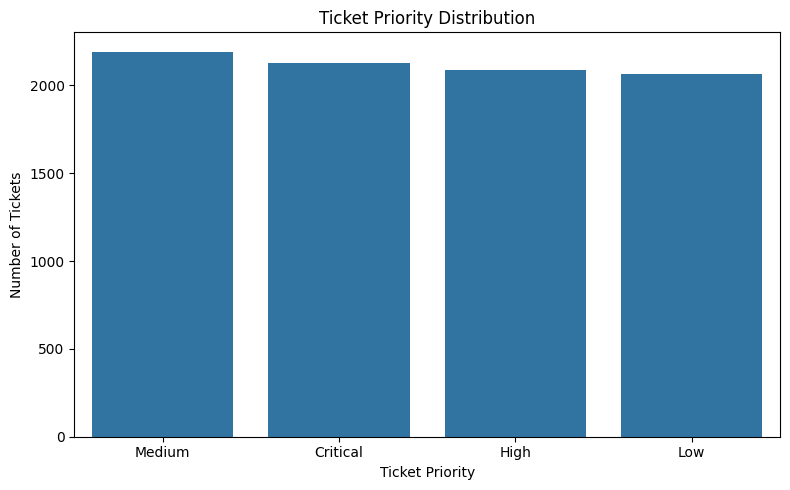

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="Ticket Priority",
    order=df["Ticket Priority"].value_counts().index
)
plt.title("Ticket Priority Distribution")
plt.xlabel("Ticket Priority")
plt.ylabel("Number of Tickets")
plt.tight_layout()
plt.show()

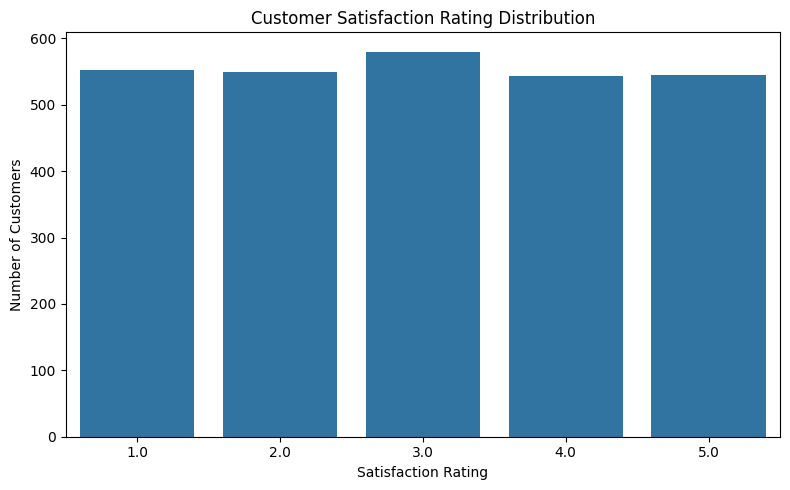

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df.dropna(subset=["Customer Satisfaction Rating"]),
    x="Customer Satisfaction Rating"
)
plt.title("Customer Satisfaction Rating Distribution")
plt.xlabel("Satisfaction Rating")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()